# 02 – Vẽ biểu đồ

**Mục tiêu** – vẽ đúng các đồ thị đề bài yêu cầu, đạt chuẩn báo cáo:
1. Tốc độ đếm trung bình tích lũy $r_c(j)$ (mục 2.3 bước 1) – kỹ thuật `np.cumsum`, `fill_between`.
2. Bảng tần suất – `np.bincount` / `value_counts`.
3. Histogram thực nghiệm **dạng điểm có thanh sai số** + Poisson **dạng đường** (bước 3, Hình 3 trong đề) – `plt.errorbar`.
4. Chồng phân bố Gauss (bước 5).
5. Nhiều đồ thị con (`subplots`), lưu hình (`savefig`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from du_lieu import doc_so_lieu, TEN_BO, T_NGAN, T_DAI   # module đọc số liệu (xem notebook 01)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
data, N100 = doc_so_lieu()
data.head()

,S1,S2,S3
lan_do,,,
1,10,40,126
2,9,26,115
3,7,33,109
4,9,34,128
5,5,37,134


## 1. Tốc độ đếm trung bình tích lũy

$$r_c(j)=\frac{\sum_{i=1}^{j}x_i}{\sum_{i=1}^{j}t_i}$$

💡 **Kỹ thuật vector hóa:** không cần vòng `for` – `np.cumsum(x)` cho tổng tích lũy $\sum_{i\le j}x_i$ của mọi $j$ cùng lúc.

In [2]:
x = data.S3.to_numpy()
j = np.arange(1, len(x) + 1)
rc = np.cumsum(x) / (j * T_NGAN)          # mọi t_i = 10 s nên Σt_i = 10·j
print(rc[:5], "...", rc[-1])

[12.6        12.05       11.66666667 11.95       12.24      ] ... 11.219


Để biết dao động của $r_c(j)$ có “bình thường” không, vẽ thêm **dải ±1σ Poisson**: tổng $j$ lần đếm có
$\sigma = \sqrt{\mu j}$ nên $\sigma_{r_c}=\sqrt{\mu j}/(j\,t)$.

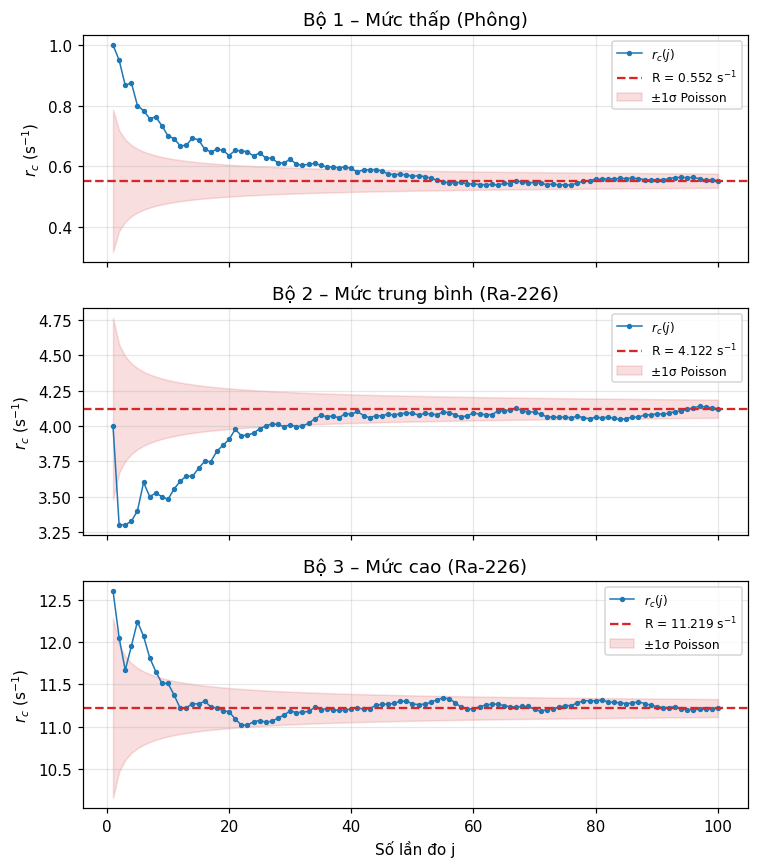

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(7, 8), sharex=True)
for ax, bo in zip(axes, data):
    x = data[bo].to_numpy()
    rc = np.cumsum(x) / (j * T_NGAN)
    R = x.mean() / T_NGAN
    band = np.sqrt(x.mean() * j) / (j * T_NGAN)
    ax.plot(j, rc, "o-", ms=2.5, lw=1, label="$r_c(j)$")
    ax.axhline(R, color="C3", ls="--", label=f"R = {R:.3f} s$^{{-1}}$")
    ax.fill_between(j, R - band, R + band, color="C3", alpha=0.15, label="±1σ Poisson")
    ax.set_title(TEN_BO[bo]); ax.set_ylabel("$r_c$ (s$^{-1}$)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[-1].set_xlabel("Số lần đo j")
fig.tight_layout()

**Đọc đồ thị:** $r_c(j)$ dao động mạnh lúc đầu rồi đi vào dải ±1σ và hội tụ → quá trình **dừng**.
Nếu đường cong trôi dần ra khỏi dải (ví dụ nguồn bị xê dịch, điện áp trôi) thì quá trình không dừng.

## 2. Bảng tần suất

Hai cách tương đương:
- `np.bincount(x)` – đếm số lần xuất hiện của 0, 1, 2, … (nhanh, cho số nguyên không âm).
- `pd.Series(x).value_counts().sort_index()` – chỉ liệt kê giá trị có xuất hiện.

In [4]:
x = data.S1.to_numpy()
print("bincount :", np.bincount(x))
pd.Series(x).value_counts().sort_index().rename("O_k").to_frame().T

bincount : [ 0  4  8  9 14 14 21 13  2  8  5  0  2]


,1,2,3,4,5,6,7,8,9,10,12
O_k,4,8,9,14,14,21,13,2,8,5,2


In [5]:
def bang_tan_suat(x):
    """Trả về (k, O): k chạy liên tục từ min đến max, O là số lần xuất hiện (kể cả 0)."""
    k = np.arange(x.min(), x.max() + 1)
    O = np.bincount(x, minlength=x.max() + 1)[k]
    return k, O

k, O = bang_tan_suat(data.S1.to_numpy())
mu = data.S1.mean()
pd.DataFrame({"k": k, "O_k": O, "E_k Poisson": len(x) * stats.poisson.pmf(k, mu)}).round(2).T

,0,1,2,3,4,5,6,7,8,9,10,11
k,1.00,2.0,3.00,4.0,5.00,6.00,7.00,8.00,9.00,10.0,11.00,12.00
O_k,4.00,8.0,9.00,14.0,14.00,21.00,13.00,2.00,8.00,5.0,0.00,2.00
E_k Poisson,2.21,6.1,11.23,15.5,17.11,15.74,12.41,8.56,5.25,2.9,1.46,0.67


## 3. Thực nghiệm (điểm + thanh sai số) và Poisson (đường)

- Tần suất lý thuyết **chuẩn hóa** theo số lần đo: $E_k = n\cdot P(k;\bar x)$ – dùng `stats.poisson.pmf`.
- Thanh sai số của tần suất đếm: $\pm\sqrt{O_k}$ – dùng `plt.errorbar(..., yerr=...)`.
- Poisson là phân bố **rời rạc**: tính tại các số nguyên rồi nối thành đường cho dễ nhìn.

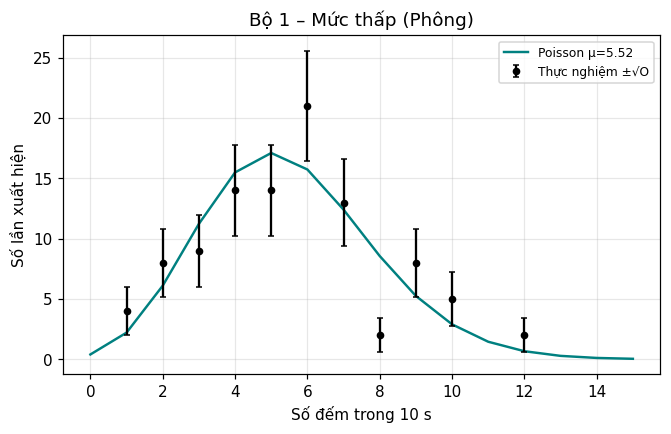

In [6]:
def ve_phan_bo(ax, x, ten, gauss=False):
    n, mu = len(x), x.mean()
    k, O = bang_tan_suat(x)
    kk = np.arange(max(0, k.min() - 3), k.max() + 4)
    ax.plot(kk, n * stats.poisson.pmf(kk, mu), "-", color="teal", lw=1.6, label=f"Poisson µ={mu:.2f}")
    if gauss:
        xs = np.linspace(kk.min(), kk.max(), 400)
        ax.plot(xs, n * stats.norm.pdf(xs, mu, np.sqrt(mu)), "--", color="C1", label="Gauss µ=σ²")
    m = O > 0                                   # chỉ vẽ điểm có số liệu
    ax.errorbar(k[m], O[m], yerr=np.sqrt(O[m]), fmt="o", ms=4, color="k", capsize=2, label="Thực nghiệm ±√O")
    ax.set(title=ten, xlabel="Số đếm trong 10 s", ylabel="Số lần xuất hiện")
    ax.grid(alpha=.3); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(7, 4))
ve_phan_bo(ax, data.S1.to_numpy(), TEN_BO["S1"])

## 4. Ba bộ trên cùng một hình + chồng Gauss

💡 **Kỹ thuật:** viết hàm vẽ nhận `ax` làm tham số → dùng lại được cho mọi bộ và mọi bố cục `subplots`.

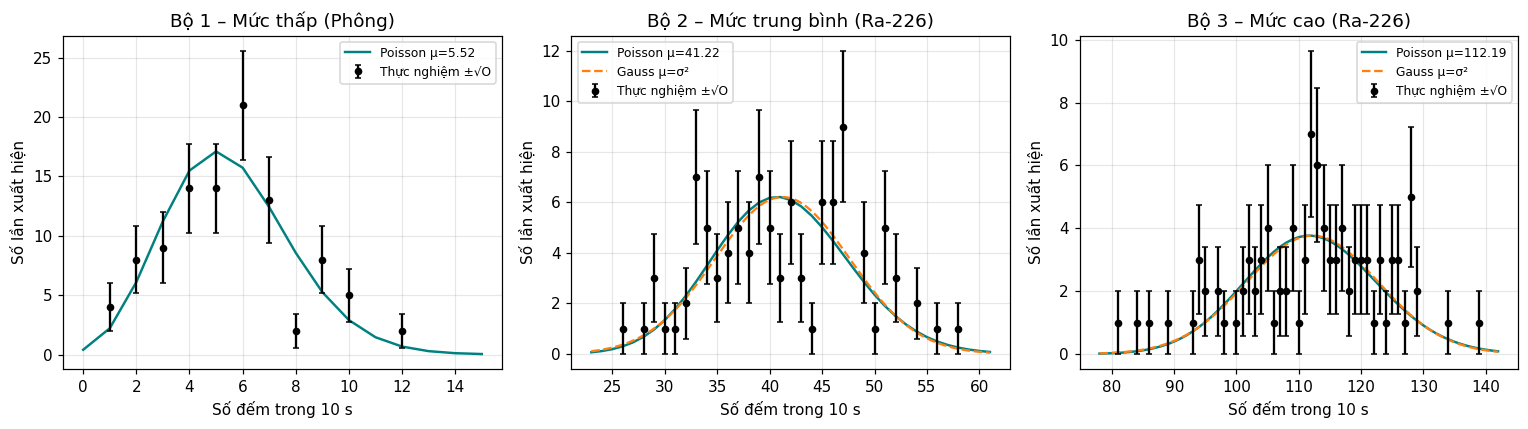

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, bo in zip(axes, data):
    ve_phan_bo(ax, data[bo].to_numpy(), TEN_BO[bo], gauss=(bo != "S1"))
fig.tight_layout()

**Nhận xét:** ở µ ≈ 5,5 phân bố lệch rõ (đuôi phải dài) – Gauss không phù hợp; ở µ ≈ 41 Gauss lệch nhẹ khỏi Poisson; ở µ ≈ 112 hai đường gần trùng.

## 5. So sánh trực quan Poisson – Gauss theo µ

Vẽ lý thuyết với nhiều giá trị µ để thấy Poisson tiến dần tới Gauss.

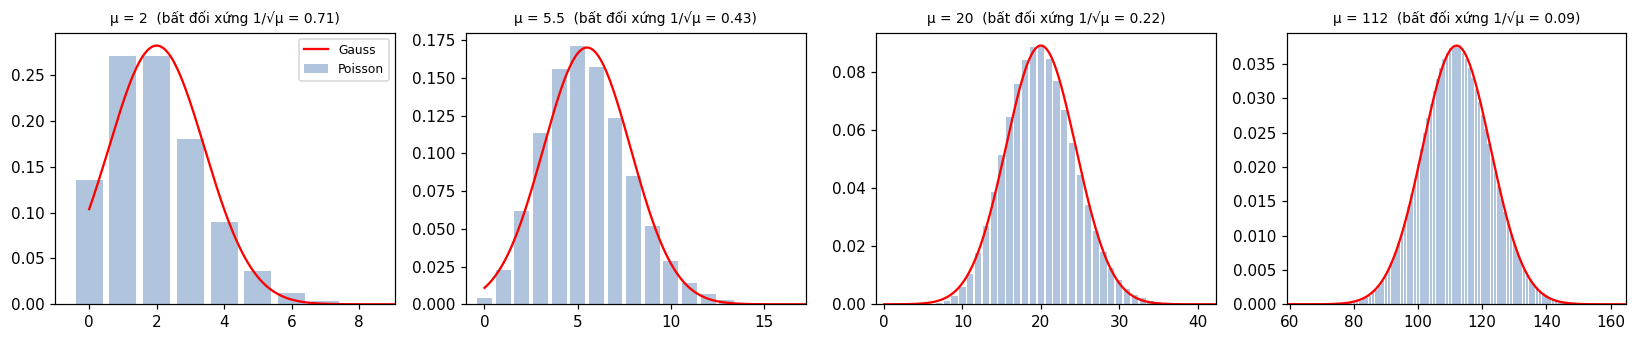

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, mu in zip(axes, [2, 5.5, 20, 112]):
    k = np.arange(0, int(mu + 5 * np.sqrt(mu)) + 3)
    ax.bar(k, stats.poisson.pmf(k, mu), color="lightsteelblue", label="Poisson")
    xs = np.linspace(k.min(), k.max(), 400)
    ax.plot(xs, stats.norm.pdf(xs, mu, np.sqrt(mu)), "r-", label="Gauss")
    ax.set_title(f"µ = {mu}  (bất đối xứng 1/√µ = {1/np.sqrt(mu):.2f})", fontsize=9)
    ax.set_xlim(max(-1, mu - 5 * np.sqrt(mu)), mu + 5 * np.sqrt(mu))
axes[0].legend(fontsize=8); fig.tight_layout()

## 6. Lưu hình cho báo cáo

- `dpi=200–300` cho bản in; định dạng `png` (ảnh) hoặc `pdf`/`svg` (vector, nét khi phóng to).
- `bbox_inches="tight"` cắt bớt lề trắng.

In [9]:
from pathlib import Path
THU_MUC_HINH = Path("hinh_tu_ve"); THU_MUC_HINH.mkdir(exist_ok=True)
fig.savefig(THU_MUC_HINH / "poisson_vs_gauss.png", dpi=200, bbox_inches="tight")
print("Đã lưu:", sorted(p.name for p in THU_MUC_HINH.iterdir()))

Đã lưu: ['poisson_vs_gauss.png']


## 📝 Bài tập
1. Vẽ $r_c(j)$ của cả 3 bộ trên **cùng một trục**, chia mỗi đường cho tốc độ trung bình của bộ đó ($r_c/R$) để so sánh tốc độ hội tụ.
2. Vẽ histogram Bộ 3 với **bin rộng 5 số đếm** (gộp bin). Khi gộp bin, $E$ lý thuyết phải tính thế nào? *(Gợi ý: cộng `pmf` trong bin, hoặc dùng `stats.poisson.cdf`.)*
3. Vẽ đồ thị **phần dư chuẩn hóa** $(O_k-E_k)/\sqrt{E_k}$ theo $k$ cho Bộ 2. Khoảng bao nhiêu % điểm nằm ngoài ±2?